In [5]:
import os
import torch
from torchvision.transforms import ToTensor, Resize, Compose

import numpy as np
import pandas as pd
import pickle
from tqdm import tqdm
import ot

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import torch.nn.functional as F

import timm
import tifffile

import scanpy
import novae

import matplotlib.pyplot as plt

In [6]:
# tissue_type = "lung_cancer"
# image_file = "../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/Xenium_Prime_Human_Lung_Cancer_FFPE_he_image.ome.tif"
# transform_for_alignment = np.loadtxt("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/Xenium_Prime_Human_Lung_Cancer_FFPE_he_imagealignment.csv", delimiter=",")
# spatial_data = scanpy.read_10x_h5("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/cell_feature_matrix.h5")
# cells_df = pd.read_csv("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/cells.csv.gz")


# tissue_type = "breast_cancer"
# image_file = "../../data/Xenium_Prime_Breast_Cancer_FFPE/Xenium_Prime_Breast_Cancer_FFPE_he_image.ome.tif"
# transform_for_alignment = np.loadtxt("../../data/Xenium_Prime_Breast_Cancer_FFPE/Xenium_Prime_Breast_Cancer_FFPE_he_imagealignment.csv", delimiter=",")
# spatial_data = scanpy.read_10x_h5("../../data/Xenium_Prime_Breast_Cancer_FFPE/cell_feature_matrix.h5")
# cells_df = pd.read_csv("../../data/Xenium_Prime_Breast_Cancer_FFPE/cells.csv.gz")

In [7]:
# ===== Load image data ===== 
image_data = tifffile.imread(image_file)

# ref: https://kb.10xgenomics.com/hc/en-us/articles/35386990499853-How-can-I-convert-coordinates-between-H-E-image-and-Xenium-data?utm_source=chatgpt.com

transform_inv = np.linalg.inv(transform_for_alignment)

# ===== Load spatial data ===== 
# Extract x, y
x = cells_df["x_centroid"] / 0.2125
y = cells_df["y_centroid"] / 0.2125

# Make homogeneous coordinates: shape (3, N)
xy_hom = np.vstack([x.to_numpy(), y.to_numpy(), np.ones_like(x)])

# Apply affine transformation
xy_aligned = transform_inv @ xy_hom

# Save results back to DataFrame
cells_df["x_pixel"] = xy_aligned[1]
cells_df["y_pixel"] = xy_aligned[0]

cells_df.set_index("cell_id", inplace=True)

spatial_data.obs = cells_df.loc[spatial_data.obs_names].copy()

spatial_data.obsm["spatial"] = spatial_data.obs[["x_pixel", "y_pixel"]].to_numpy()

In [8]:
image_data.shape

(37433, 57382, 3)

In [9]:
spatial_data.obs.loc[:,['x_pixel','y_pixel']].max()

x_pixel    38744.161331
y_pixel    56805.687826
dtype: float64

In [10]:
spatial_data.obs.loc[:,['x_pixel','y_pixel']].min()

x_pixel    -741.285165
y_pixel   -1109.512328
dtype: float64

In [11]:
spatial_data.obsm["spatial"].max(axis=0)

array([38744.16133056, 56805.68782594])

# Get pretrained model

In [12]:
x1 = spatial_data

# Spatial encoder
spatial_encoder = novae.Novae.from_pretrained("MICS-Lab/novae-human-0")

# spatial embedding
novae.spatial_neighbors(x1, radius=80)
spatial_encoder.compute_representations(
    x1, zero_shot=True
)  # x should be adata

[INFO] (novae.utils._build) Computing graph on 699,110 cells (coord_type=generic, delaunay=True, radius=[0.0, 80.0], n_neighs=None)
/Users/dabin/Library/Caches/pypoetry/virtualenvs/model-SeWCCRZy-py3.12/lib/python3.12/site-packages/scanpy/preprocessing/_normalization.py:243: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))
[INFO] (novae.utils._validate) Preprocessed 1 adata object(s) with sc.pp.normalize_total and sc.pp.log1p (raw counts were saved in adata.layers['counts'])
Computing representations: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1333/1333 [18:59<00:00,  1.17it/s]


In [13]:
# Image encoder
pretrained_ckpt_dir = "../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/"

os.listdir("../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/")

os.makedirs(pretrained_ckpt_dir, exist_ok=True)

image_encoder = timm.create_model(
    "vit_large_patch16_224",
    img_size=224,
    patch_size=16,
    init_values=1e-5,
    num_classes=0,
    dynamic_img_size=True,
)
image_encoder.load_state_dict(
    torch.load(
        os.path.join(pretrained_ckpt_dir, "pytorch_model.bin"), map_location="cpu"
    ),
    strict=True,
)
image_encoder.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): 

# Sinlge FOV embedding

In [14]:
fov_size = 256

x_start, y_start = 2000, 1000

In [15]:
transform = Compose([
    ToTensor(), 
    Resize((224, 224)) # → Resize for ViT input
])

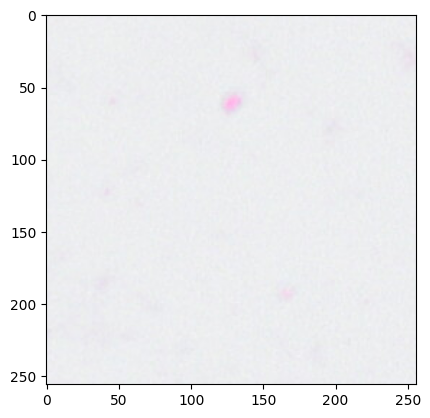

In [16]:
plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.show()

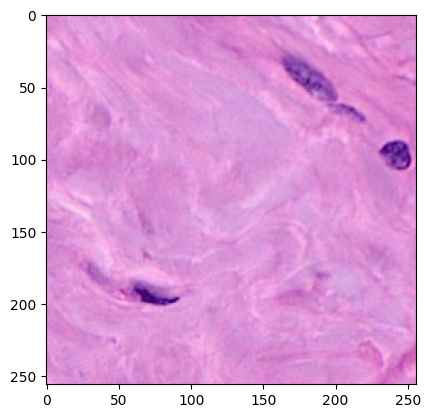

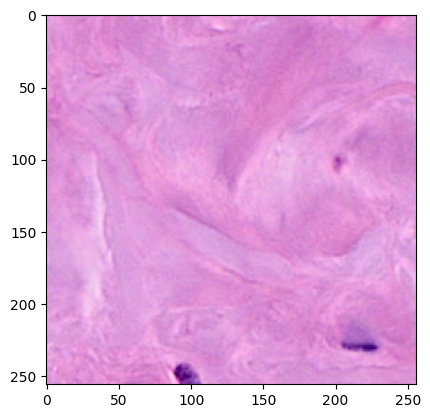

In [17]:
# Morphology similar, cell embedding similar: 2000, 1000
# Morphology NOT similar, cell embedding similar: 2500,3000

x_start, y_start = 20000, 10000
plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.show()

plt.imshow(image_data[x_start+fov_size:x_start+2*fov_size,y_start:y_start+fov_size,:])
plt.show()

In [18]:
fov_image_A = image_data[x_start:x_start+fov_size, y_start:y_start+fov_size, :]
fov_image_B = image_data[x_start+fov_size:x_start+2*fov_size,y_start:y_start+fov_size,:]

x_A = transform(fov_image_A).unsqueeze(0)
x_B = transform(fov_image_B).unsqueeze(0)
with torch.no_grad():
    image_embedding_A = image_encoder(x_A)
    image_embedding_B = image_encoder(x_B)

F.cosine_similarity(image_embedding_A, image_embedding_B)

tensor([0.7214])

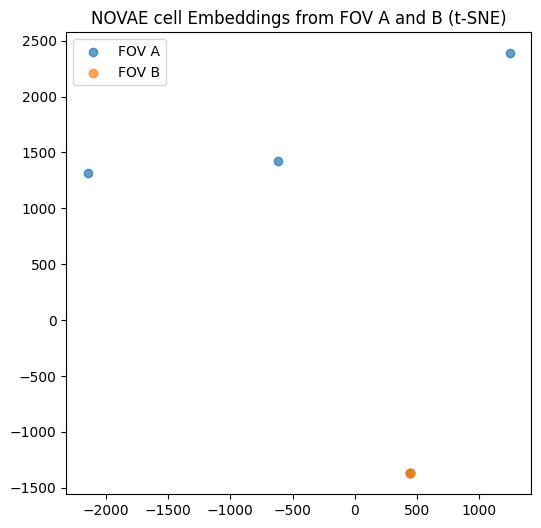

In [19]:
points = x1.obsm['spatial']

mask = (
    (x_start <= points[:,0]) & (points[:,0] < x_start + fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

FOV_A = x1.obsm["novae_latent"][mask]

mask = (
    (x_start + fov_size <= points[:,0]) & (points[:,0] < x_start + 2*fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

FOV_B = x1.obsm["novae_latent"][mask]

# 합치기
all_cells = np.concatenate([FOV_A, FOV_B], axis=0)

# t-SNE 적용
tsne = TSNE(n_components=2, perplexity=3, random_state=42)
all_embedded = tsne.fit_transform(all_cells)

# 분리
A_emb = all_embedded[:len(FOV_A)]
B_emb = all_embedded[len(FOV_A):]

# 시각화
plt.figure(figsize=(6, 6))
plt.scatter(A_emb[:, 0], A_emb[:, 1], label='FOV A', alpha=0.7)
plt.scatter(B_emb[:, 0], B_emb[:, 1], label='FOV B', alpha=0.7)
plt.legend()
plt.title("NOVAE cell Embeddings from FOV A and B (t-SNE)")
plt.show()

In [20]:
FOV_A.shape

(5, 64)

In [21]:
FOV_B.shape

(2, 64)

In [22]:
a = np.ones(FOV_A.shape[0]) / FOV_A.shape[0]
b = np.ones(FOV_B.shape[0]) / FOV_B.shape[0]

M = ot.dist(FOV_A, FOV_B, metric='euclidean')

# Compute Wasserstein distance
print(ot.emd2(a, b, M))

# Compute cosine similarity
print(F.cosine_similarity(torch.tensor(FOV_A.mean(axis=0)).unsqueeze(0), torch.tensor(FOV_B.mean(axis=0)).unsqueeze(0)))

0.8389592170715331
tensor([0.])


In [23]:
points = x1.obsm['spatial']

mask = (
    (x_start <= points[:,0]) & (points[:,0] < x_start + fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

spatial_embedding = torch.Tensor(x1.obsm["novae_latent"][mask]).mean(axis=0).unsqueeze(0)

x2 = transform(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:]).unsqueeze(0)

# image embedding
image_embedding = image_encoder(x2)

# Multiple FOV embeddings --> manifold

In [ ]:
slide_H, slide_W, _ = image_data.shape
fov_size = 256
stride = 256  

fov_coords = []
for x in range(0, slide_H - fov_size + 1, stride):
    for y in range(0, slide_W - fov_size + 1, stride):
        fov_coords.append((x, y))


spatial_embeddings = []
image_embeddings = []

for x_start, y_start in tqdm(fov_coords):
    # 1. spatial embedding (cells inside this FOV)
    mask = (
        (x_start <= points[:, 0]) & (points[:, 0] < x_start + fov_size) &
        (y_start <= points[:, 1]) & (points[:, 1] < y_start + fov_size)
    )
    if mask.sum() == 0:
        continue  # skip empty regions
    
    spatial_embedding = torch.Tensor(x1.obsm["novae_latent"][mask]).mean(dim=0).unsqueeze(0)
    spatial_embeddings.append(spatial_embedding)

    # 2. image embedding
    fov_image = image_data[x_start:x_start+fov_size, y_start:y_start+fov_size, :]
    x2 = transform(fov_image).unsqueeze(0)
    with torch.no_grad():
        image_embedding = image_encoder(x2)
    image_embeddings.append(image_embedding)

  4%|████████▎                                                                                                                                                                                                                         | 1196/32704 [02:36<2:26:25,  3.59it/s]

In [ ]:
stacked_spatial_embeddings = torch.stack(spatial_embeddings).squeeze(1)

In [ ]:
stacked_image_embeddings = torch.stack(image_embeddings).squeeze(1)

In [ ]:
stacked_image_embeddings.shape

In [ ]:
# with open(f"./spatial_embeddings_{tissue_type}.pkl", "wb") as f:
#     pickle.dump(stacked_spatial_embeddings, f)

# with open(f"./image_embeddings_{tissue_type}.pkl", "wb") as f:
#     pickle.dump(stacked_image_embeddings, f)

In [ ]:
with open(f"./spatial_embeddings_{tissue_type}.pkl", "rb") as f:
    stacked_spatial_embeddings = pickle.load(f)

with open(f"./image_embeddings_{tissue_type}.pkl", "rb") as f:
    stacked_image_embeddings = pickle.load(f)

In [ ]:
stacked_spatial_embeddings.shape

In [ ]:
stacked_image_embeddings.shape

In [ ]:
def get_null_distribution(embeddings: torch.Tensor, num_samples: int = 1000, seed: int = 42):

    if seed is not None:
        torch.manual_seed(seed)

    N = embeddings.size(0)
    similarities = []

    for _ in range(num_samples):
        i, j = torch.randint(0, N, (2,))
        vec_i = embeddings[i].unsqueeze(0)  # shape (1, D)
        vec_j = embeddings[j].unsqueeze(0)
        sim = F.cosine_similarity(vec_i, vec_j).item()
        similarities.append(sim)

    return torch.tensor(similarities)

image_cosine_sim_null_dist = get_null_distribution(stacked_image_embeddings)
spatial_cosine_sim_null_dist = get_null_distribution(stacked_spatial_embeddings)

In [ ]:
image_cosine_sim_null_dist.median()

In [ ]:
spatial_cosine_sim_null_dist.median()

In [ ]:
target = F.cosine_similarity(image_embedding_A, image_embedding_B)
sum(image_cosine_sim_null_dist >= target) / len(image_cosine_sim_null_dist)

In [ ]:
target = F.cosine_similarity(torch.tensor(FOV_A.mean(axis=0)).unsqueeze(0), torch.tensor(FOV_B.mean(axis=0)).unsqueeze(0))
sum(spatial_cosine_sim_null_dist >= target) / len(spatial_cosine_sim_null_dist)

# Plot

In [ ]:
A, B = stacked_spatial_embeddings.detach().numpy(), stacked_image_embeddings.detach().numpy()

scaler = StandardScaler()
A = scaler.fit_transform(A)
B = scaler.fit_transform(B)

# Step 1: 먼저 A, B 각각을 낮은 차원 (예: 5)으로 줄임
pca_A = PCA(n_components=5).fit_transform(A)
pca_B = PCA(n_components=5).fit_transform(B)

# Step 2: A, B를 세로로 붙여서 같이 PCA (같은 feature 수니까 가능)
AB = np.concatenate([pca_A, pca_B], axis=0)  # shape = (200, 50)

# Step 3: 같은 공간에 다시 PCA
joint = np.concatenate([pca_A, pca_B], axis=0)
joint_pca = PCA(n_components=2).fit_transform(joint)

pca_A_2d = joint_pca[:len(pca_A)]
pca_B_2d = joint_pca[len(pca_A):]

# 시각화
plt.figure(figsize=(8, 8))
plt.scatter(pca_A[:, 0], pca_A[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.title("Spatial embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))
plt.scatter(pca_B[:, 0], pca_B[:, 1], label='Image embedding', c='orange', alpha=0.2)
plt.title("Image embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))

plt.scatter(pca_A_2d[:, 0], pca_A_2d[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.scatter(pca_B_2d[:, 0], pca_B_2d[:, 1], label='Image embedding', c='orange', alpha=0.2)

plt.scatter(pca_A_2d[100, 0], pca_A_2d[100, 1], c='red', marker='o', s=100)
plt.scatter(pca_B_2d[100, 0], pca_B_2d[100, 1], c='red', marker='o', s=100)

plt.legend()
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()